Training images: 8,225
Images with annotations: 8,225
Total annotated objects: 14,140


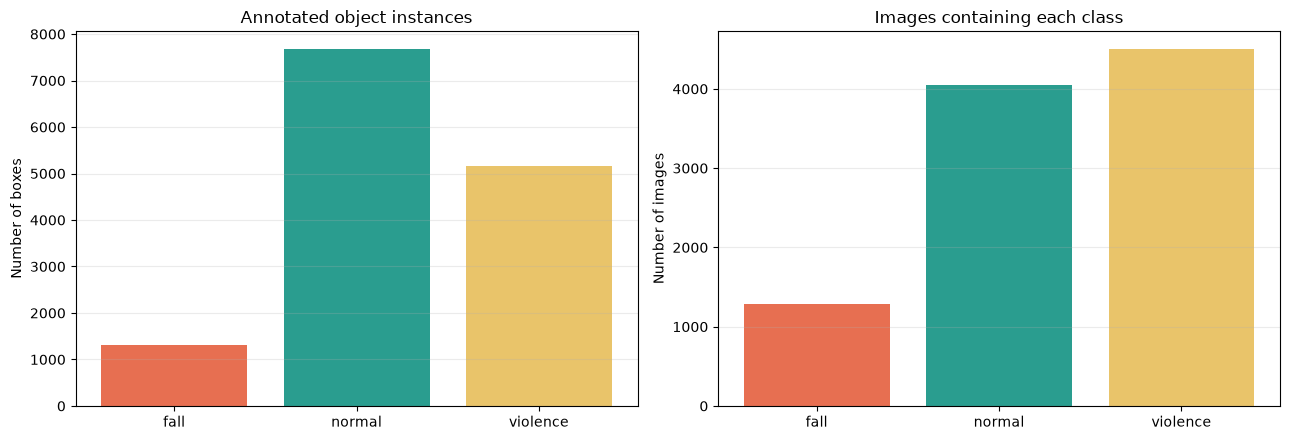

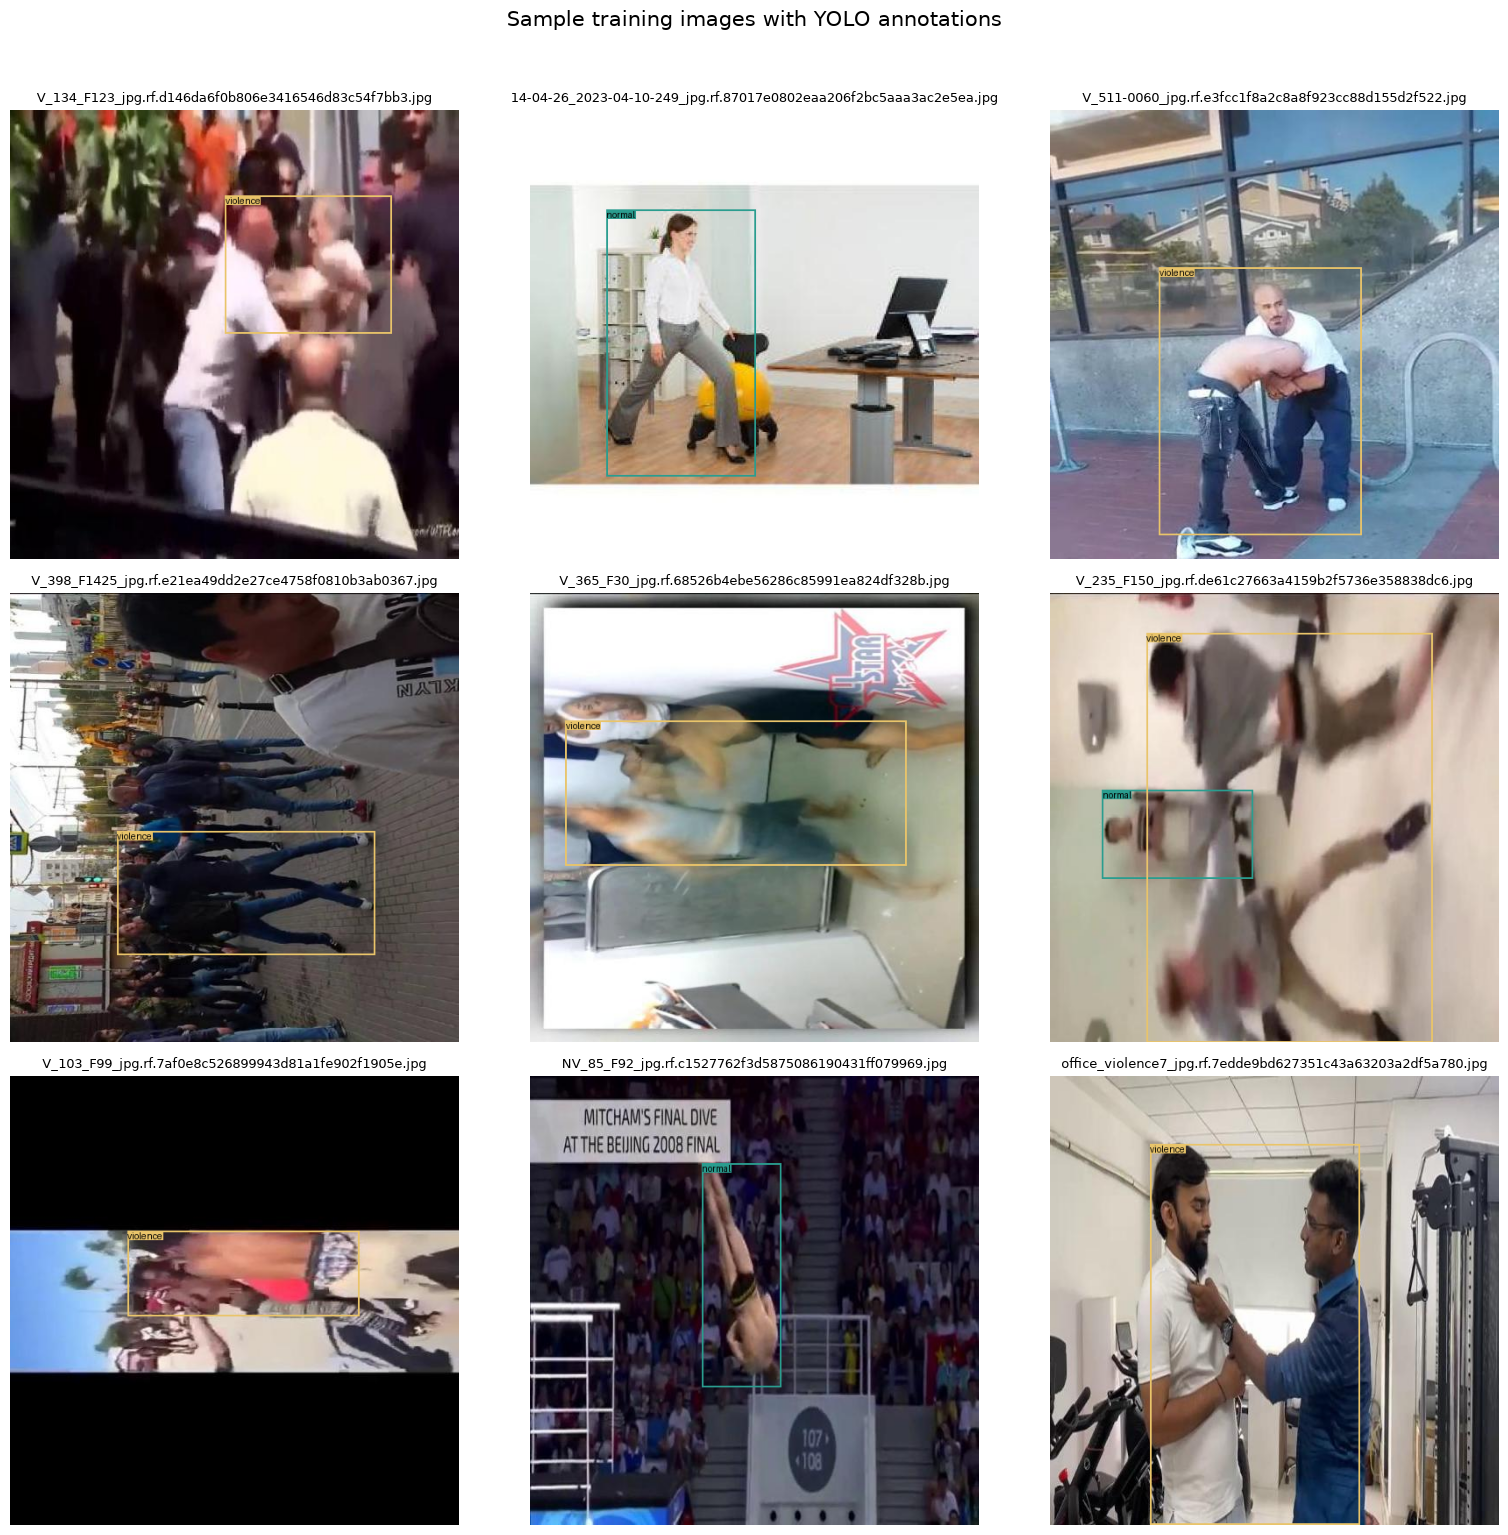

In [ ]:
from pathlib import Path
from collections import Counter
import random

import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

# Paths are relative to this notebook: violence-detection/eda.ipynb
DATASET_DIR = Path("data")
TRAIN_IMAGES_DIR = DATASET_DIR / "train" / "images"
TRAIN_LABELS_DIR = DATASET_DIR / "train" / "labels"
CLASS_NAMES = ["fall", "normal", "violence"]
COLORS = {"fall": "#e76f51", "normal": "#2a9d8f", "violence": "#e9c46a"}

if not TRAIN_IMAGES_DIR.exists() or not TRAIN_LABELS_DIR.exists():
    raise FileNotFoundError(
        f"Expected train folders at {TRAIN_IMAGES_DIR} and {TRAIN_LABELS_DIR}. "
        "Run this notebook from the violence-detection directory."
    )

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
image_paths = sorted(
    path for path in TRAIN_IMAGES_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
)

# Read YOLO label files: class_id, x_center, y_center, width, height.
labels_by_image = {}
instance_counts = Counter()
image_counts = Counter()

for image_path in image_paths:
    label_path = TRAIN_LABELS_DIR / f"{image_path.stem}.txt"
    image_labels = []

    if label_path.exists():
        for line_number, line in enumerate(label_path.read_text().splitlines(), start=1):
            values = line.split()
            # if len(values) != 5:
            #     print(f"Skipping malformed row in {label_path.name}:{line_number}")
            #     continue

            class_id = int(values[0])
            # if not 0 <= class_id < len(CLASS_NAMES):
            #     print(f"Skipping unknown class {class_id} in {label_path.name}:{line_number}")
            #     continue

            box = tuple(float(value) for value in values[1:])
            image_labels.append((class_id, box))
            instance_counts[class_id] += 1

    labels_by_image[image_path] = image_labels
    image_counts.update({class_id for class_id, _ in image_labels})

print(f"Training images: {len(image_paths):,}")
print(f"Images with annotations: {len(labels_by_image):,}")
print(f"Total annotated objects: {sum(instance_counts.values()):,}")

# Compare object instances with the number of images containing each class.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
class_labels = CLASS_NAMES
bar_colors = [COLORS[name] for name in class_labels]

axes[0].bar(
    class_labels,
    [instance_counts[class_id] for class_id in range(len(CLASS_NAMES))],
    color=bar_colors,
)
axes[0].set_title("Annotated object instances")
axes[0].set_ylabel("Number of boxes")
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(
    class_labels,
    [image_counts[class_id] for class_id in range(len(CLASS_NAMES))],
    color=bar_colors,
)
axes[1].set_title("Images containing each class")
axes[1].set_ylabel("Number of images")
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


def draw_yolo_annotations(image_path, image_labels):
    """Return an image with normalized YOLO boxes and class names drawn on it."""
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    image_width, image_height = image.size

    for class_id, (x_center, y_center, box_width, box_height) in image_labels:
        left = (x_center - box_width / 2) * image_width
        top = (y_center - box_height / 2) * image_height
        right = (x_center + box_width / 2) * image_width
        bottom = (y_center + box_height / 2) * image_height
        class_name = CLASS_NAMES[class_id]
        color = COLORS[class_name]

        draw.rectangle((left, top, right, bottom), outline=color, width=max(2, image_width // 250))
        text = class_name
        text_box = draw.textbbox((left, top), text)
        draw.rectangle(text_box, fill=color)
        draw.text((left, top), text, fill="black")

    return image

# Show a reproducible sample of training images with their ground-truth annotations.
rng = random.Random(42)
annotated_images = [path for path in image_paths if labels_by_image[path]]
sample_size = min(9, len(annotated_images))
sample_paths = rng.sample(annotated_images, sample_size)

columns = 3
rows = (sample_size + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(16, 5 * rows))
axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

for axis, image_path in zip(axes, sample_paths):
    axis.imshow(draw_yolo_annotations(image_path, labels_by_image[image_path]))
    axis.set_title(image_path.name, fontsize=9)
    axis.axis("off")

for axis in axes[sample_size:]:
    axis.axis("off")

plt.suptitle("Sample training images with YOLO annotations", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()


In [ ]:
from ultralytics import YOLO

# Run this notebook from the violence-detection directory.
DATA_CONFIG = "data/data.yaml"
MODEL_NAME = "yolo26s.pt"

# Load pretrained YOLO26s weights and fine-tune on the configured dataset.
model = YOLO(MODEL_NAME)
training_results = model.train(
    data=DATA_CONFIG,
    epochs=50,
    imgsz=640,
    batch=-1,          # Automatically use the largest safe batch size.
    device=0,          # Use the first GPU; change to "cpu" if no CUDA GPU is available.
    workers=4,
    patience=15,
    project="runs/train",
    name="yolo26s-violence",
    exist_ok=True,
    pretrained=True,
    seed=42,
)

# Evaluate the best checkpoint on the validation split.
best_model = YOLO("runs/train/yolo26s-violence/weights/best.pt")
metrics = best_model.val(data=DATA_CONFIG, imgsz=640, device=0)
print(f"mAP50-95: {metrics.box.map:.4f}")
print(f"mAP50:    {metrics.box.map50:.4f}")

# Visualize predictions on a few validation images.
best_model.predict(
    source="data/valid/images",
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project="runs/predict",
    name="yolo26s-violence-valid",
    exist_ok=True,
    max_det=100,
)
